# Phân tích RFM khách hàng ngân hàng

Mục tiêu: chia nhóm khách hàng để đề xuất hoạt động CRM. Dữ liệu giả lập từ đề bài, không phải hồ sơ ngân hàng thật.

- Ngày đánh giá: **01/10/2026**. Kỳ quan sát: **01/10/2025 - 30/09/2026**.
- Một dòng kết quả tương ứng một khách hàng.
- M là tổng giá trị giao dịch chi ra, **không phải doanh thu hoặc lợi nhuận ngân hàng**.
- Không dùng `synthetic_profile_hint` làm đầu vào hoặc nhãn đánh giá.

Chạy các ô từ trên xuống dưới tại folder chứa hai file CSV.


In [1]:
from os import makedirs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

as_of = pd.Timestamp('2026-10-01')
start = pd.Timestamp('2025-10-01')
makedirs('output/charts', exist_ok=True)

customers = pd.read_csv('customers.csv')
transactions = pd.read_csv('transactions.csv')
print('Customers:', customers.shape)
print('Transactions:', transactions.shape)
customers = customers.drop(columns='synthetic_profile_hint')
print(customers.head())
print(transactions.head())


Customers: (1000, 6)
Transactions: (43711, 7)
  customer_id   open_date       city age_band onboarding_channel
0      C00001  2025-10-07  Hai Phong    18-25             Branch
1      C00002  2025-11-03      Hanoi    36-50                Web
2      C00003  2026-02-10      Hanoi    36-50             Mobile
3      C00004  2025-09-23  Hai Phong    18-25             Mobile
4      C00005  2025-07-07    Da Nang      51+             Branch
  transaction_id customer_id transaction_date transaction_type  amount_vnd  \
0       T0026940      C00606       2026-05-04     CARD_PAYMENT      818000   
1       T0006584      C00156       2026-03-15   ATM_WITHDRAWAL     1493000   
2       T0033305      C00756       2025-07-26     BILL_PAYMENT      432000   
3       T0040551      C00921       2026-04-10      TRANSFER_IN      620000   
4       T0028712      C00646       2025-08-25     TRANSFER_OUT       95000   

    status channel  
0  SUCCESS     POS  
1  SUCCESS     POS  
2  SUCCESS     POS  
3  SUCCESS 

## 1. Khám phá và làm sạch

Kiểm tra dữ liệu thiếu, dòng trùng và trạng thái. Giữ bản gốc trong `transactions` để đối chiếu. Các thuộc tính thành phố, tuổi và kênh đăng ký chỉ mô tả khách hàng, không dùng tính điểm.


In [2]:
print('Kiểu dữ liệu giao dịch:')
print(transactions.dtypes.to_frame('dtype'))
print('Giá trị thiếu:')
print(customers.isna().sum().to_frame('missing'))
print(transactions.isna().sum().to_frame('missing'))
print('Khách trùng mã:', customers.customer_id.duplicated().sum())
print('Giao dịch trùng mã:', transactions.transaction_id.duplicated().sum())
print('Dòng giao dịch trùng toàn bộ:', transactions.duplicated().sum())
print(transactions.status.value_counts().to_frame('count'))
print(transactions.transaction_type.value_counts().to_frame('count'))


Kiểu dữ liệu giao dịch:
                   dtype
transaction_id    object
customer_id       object
transaction_date  object
transaction_type  object
amount_vnd         int64
status            object
channel           object
Giá trị thiếu:
                    missing
customer_id               0
open_date                 0
city                      0
age_band                  0
onboarding_channel        0
                  missing
transaction_id          0
customer_id             0
transaction_date       15
transaction_type        0
amount_vnd              0
status                  0
channel                 0
Khách trùng mã: 0
Giao dịch trùng mã: 35
Dòng giao dịch trùng toàn bộ: 35
          count
status         
SUCCESS   41070
FAILED     1715
REVERSED    926
                  count
transaction_type       
CARD_PAYMENT      14006
TRANSFER_OUT      10011
TRANSFER_IN        6987
BILL_PAYMENT       6177
ATM_WITHDRAWAL     4400
CASH_DEPOSIT       2130


**Quyết định làm sạch:**

1. Các dòng trùng mã trong bộ dữ liệu này giống nhau hoàn toàn, giữ dòng đầu.
2. Bỏ ngày thiếu/không đọc được và số tiền thiếu/không hữu hạn/không dương. Không đoán ngày hay gán tiền bằng 0.
3. Chỉ giữ `SUCCESS`; bỏ `FAILED` và `REVERSED`.
4. Chọn `CARD_PAYMENT`, `TRANSFER_OUT`, `BILL_PAYMENT`, `ATM_WITHDRAWAL`: thể hiện hoạt động chi ra. Không cộng `TRANSFER_IN`, `CASH_DEPOSIT` vì là tiền vào và có thể đếm lại cùng một dòng tiền.
5. Giới hạn ngày trong kỳ quan sát. R cũng tính trên giao dịch hợp lệ trong kỳ này.

Số bị loại được tính **tuần tự**, mỗi dòng chỉ thuộc lý do đầu tiên gặp phải; không cộng các lỗi chồng lặp.


In [ ]:
customers['open_date'] = pd.to_datetime(customers.open_date, errors='coerce')

tx = transactions.drop_duplicates('transaction_id').copy()
audit = [('Trùng transaction_id', len(transactions) - len(tx))]
tx['transaction_date'] = pd.to_datetime(tx.transaction_date, errors='coerce')
tx['amount_vnd'] = pd.to_numeric(tx.amount_vnd, errors='coerce')
open_dates = tx.customer_id.map(customers.set_index('customer_id').open_date)

eligible_types = ['CARD_PAYMENT', 'TRANSFER_OUT', 'BILL_PAYMENT', 'ATM_WITHDRAWAL']
checks = [
    ('Thiếu/ngày không hợp lệ', tx.transaction_date.isna()),
    ('Số tiền không hợp lệ hoặc <= 0', ~np.isfinite(tx.amount_vnd) | (tx.amount_vnd <= 0)),
    ('Trạng thái không SUCCESS', tx.status != 'SUCCESS'),
    ('Loại giao dịch không chọn', ~tx.transaction_type.isin(eligible_types)),
    ('Trước kỳ quan sát', tx.transaction_date < start),
    ('Từ ngày đánh giá trở đi', tx.transaction_date >= as_of)
]
for reason, mask in checks:
    before = len(tx)
    tx = tx.loc[~mask.loc[tx.index]].copy()
    audit.append((reason, before - len(tx)))

cleaning = pd.DataFrame(audit, columns=['Lý do loại', 'Số dòng'])
print(cleaning)
print('Còn lại:', len(tx), 'giao dịch')


                       Lý do loại  Số dòng
0            Trùng transaction_id       35
1         Thiếu/ngày không hợp lệ       15
2  Số tiền không hợp lệ hoặc <= 0       18
3        Trạng thái không SUCCESS     2633
4       Loại giao dịch không chọn     8559
5               Trước kỳ quan sát     5633
6         Từ ngày đánh giá trở đi        0
Còn lại: 26818 giao dịch


## 2. Tạo R, F, M ở mức khách hàng

- **R**: số ngày từ giao dịch hợp lệ gần nhất đến 01/10/2026. R thấp tốt hơn.
- **F**: số giao dịch hợp lệ trong kỳ.
- **M**: tổng tiền chi ra của các giao dịch đó, đơn vị VND.

Ghép trái từ bảng khách hàng để giữ cả người không có giao dịch hợp lệ. Với nhóm này: F = M = 0, R để trống vì chưa biết lần giao dịch gần nhất; cả ba điểm bằng 1 và xếp Hibernating. Không khẳng định họ chưa từng giao dịch trong lịch sử.


In [4]:
activity = tx.groupby('customer_id').agg(
    last_date=('transaction_date', 'max'),
    F=('transaction_id', 'count'),
    M=('amount_vnd', 'sum')
)
rfm = customers[['customer_id']].merge(activity, on='customer_id', how='left')
rfm['R'] = (as_of - rfm.last_date).dt.days.astype('Int64')
rfm['F'] = rfm.F.fillna(0).astype(int)
rfm['M'] = rfm.M.fillna(0).astype('int64')
active = rfm.F > 0
print('Có giao dịch hợp lệ:', active.sum())
print('Không có giao dịch hợp lệ:', (~active).sum())
print(rfm[['customer_id', 'R', 'F', 'M']].head(10))
print(rfm[['R', 'F', 'M']].describe())


Có giao dịch hợp lệ: 972
Không có giao dịch hợp lệ: 28
  customer_id    R   F         M
0      C00001   21   6  10829000
1      C00002   96  33  28613000
2      C00003   12  21  16544000
3      C00004  223   1   3312000
4      C00005   83  40  31441000
5      C00006   77  17  19875000
6      C00007  184   3   5763000
7      C00008   39  44  28558000
8      C00009   27  47  24912000
9      C00010   85  24  16457000
               R            F             M
count      972.0  1000.000000  1.000000e+03
mean   84.354938    26.818000  3.289025e+07
std    81.734219    20.678551  4.764423e+07
min          1.0     0.000000  0.000000e+00
25%         31.0     8.000000  6.279500e+06
50%         63.0    24.000000  1.993650e+07
75%         95.0    41.000000  3.656425e+07
max        363.0    87.000000  3.585740e+08


## 3. Chấm điểm ngũ phân vị và chia nhóm

Chỉ tính phân vị trên khách F > 0. Dùng thứ hạng trung bình (`rank(method='average', pct=True)`) rồi chia thành năm khoảng phần trăm: (0;20%], (20%;40%], ..., (80%;100%]. F, M nhận điểm 1 đến 5; R đảo thành 5 đến 1.

Các giá trị bằng nhau có cùng điểm, không tách tùy tiện theo thứ tự dòng. Do nhiều giá trị bằng nhau, mỗi nhóm điểm có thể không đúng 20% khách. Đây là cách chia ngũ phân vị theo hạng với quy tắc xử lý ties rõ ràng. R thiếu của nhóm F = 0 không được đưa vào xếp hạng. Nếu khách F > 0 thiếu R hoặc M, coi là lỗi dữ liệu và dừng.

Áp dụng các quy tắc **theo thứ tự từ trên xuống**, quy tắc đầu tiên khớp sẽ quyết định nhóm:

| Nhóm | Điều kiện |
|---|---|
| Hibernating (không hoạt động) | F = 0 |
| Champions | R_score >= 4, F_score >= 4, M_score >= 4 |
| Loyal | R_score >= 3 và F_score >= 3, chưa thuộc Champions |
| Potential | R_score >= 4, chưa thuộc hai nhóm trên |
| At Risk | R_score <= 2 và (F_score >= 3 hoặc M_score >= 3) |
| Hibernating (ít hoạt động) | R_score <= 2, chưa thuộc At Risk |
| Regular | Phần còn lại |

Nhóm Regular tránh ép các trường hợp trung bình vào năm nhóm chính. Các điều kiện cùng thứ tự ưu tiên bảo đảm mỗi khách chỉ nhận một nhóm.


In [ ]:
#@ Chia điểm 1-5 theo hạng phần trăm, giữ cùng điểm cho giá trị bằng nhau.
def quintile_score(values, reverse=False):
    scores = np.ceil(values.rank(method='average', pct=True) * 5).astype(int)
    return 6 - scores if reverse else scores

for col in ['R', 'F', 'M']:
    rfm[col + '_score'] = 1
    rfm.loc[active, col + '_score'] = quintile_score(rfm.loc[active, col], reverse=(col == 'R'))

r, f, m = rfm.R_score, rfm.F_score, rfm.M_score
rfm['segment'] = np.select(
    [~active,
     (r >= 4) & (f >= 4) & (m >= 4),
     (r >= 3) & (f >= 3),
     r >= 4,
     (r <= 2) & ((f >= 3) | (m >= 3)),
     r <= 2],
    ['Hibernating', 'Champions', 'Loyal', 'Potential', 'At Risk', 'Hibernating'],
    default='Regular'
)
print(rfm.groupby('segment').size().to_frame('customers'))
print(rfm[['R_score', 'F_score', 'M_score']].apply(pd.Series.value_counts).fillna(0).astype(int))


             customers
segment               
At Risk            184
Champions          155
Hibernating        230
Loyal              255
Potential          127
Regular             49
   R_score  F_score  M_score
1      218      213      222
2      196      210      195
3      195      194      194
4      196      189      194
5      195      194      195


In [ ]:
#? Kiểm tra hướng điểm và ties trên ví dụ nhỏ trước khi xuất kết quả.
sample = pd.Series([10, 10, 20, 30, 40, 50])
for col in ['R', 'F', 'M']:
    ordered = rfm.loc[active].sort_values(col)[col + '_score']

columns = ['customer_id', 'R', 'F', 'M', 'R_score', 'F_score', 'M_score', 'segment']
result = rfm[columns]
result.to_csv('customer_rfm.csv', index=False, encoding='utf-8-sig')
print('Đã lưu customer_rfm.csv, số dòng:', len(result))


Đã lưu customer_rfm.csv, số dòng: 1000


## 4. Quy mô nhóm, giá trị giao dịch và biểu đồ

Tỷ trọng M = tổng M của nhóm / tổng M toàn bộ khách. Trung vị R chỉ tính trên những người có giao dịch hợp lệ; trung vị F, M tính toàn nhóm, bao gồm F = 0.


In [ ]:
order = ['Champions', 'Loyal', 'Potential', 'At Risk', 'Hibernating', 'Regular']
summary = rfm.groupby('segment').agg(
    customers=('customer_id', 'size'),
    total_M=('M', 'sum'),
    median_R=('R', 'median'),
    median_F=('F', 'median'),
    median_M=('M', 'median')
).reindex(order)
summary['customer_share_pct'] = summary.customers / len(rfm) * 100
summary['M_share_pct'] = summary.total_M / rfm.M.sum() * 100
print(summary.round(2))
print('Tổng M (tỷ VND):', round(rfm.M.sum() / 1e9, 3))


             customers      total_M  median_R  median_F    median_M  \
segment                                                               
Champions          155  11293090000      23.0      49.0  44560000.0   
Loyal              255  11255058000      54.0      31.0  26011000.0   
Potential          127    885221000      27.0       8.0   6492000.0   
At Risk            184   8093399000      91.5      35.0  30882000.0   
Hibernating        230    867583000     231.0       3.5   2815000.0   
Regular             49    495901000      61.0      12.0   8815000.0   

             customer_share_pct  M_share_pct  
segment                                       
Champions                  15.5        34.34  
Loyal                      25.5        34.22  
Potential                  12.7         2.69  
At Risk                    18.4        24.61  
Hibernating                23.0         2.64  
Regular                     4.9         1.51  
Tổng M (tỷ VND): 32.89


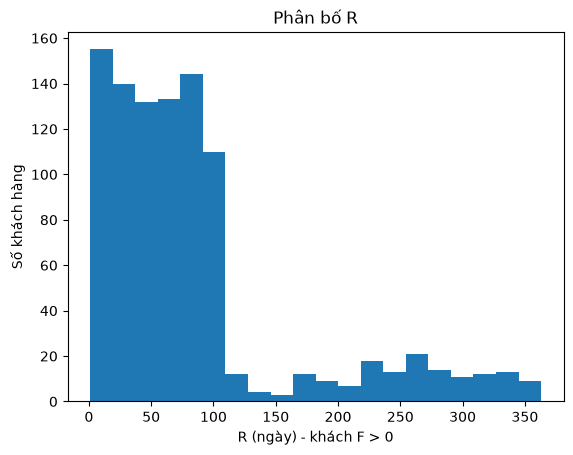

In [8]:
plt.hist(rfm.loc[active, 'R'].astype(int), bins=20)
plt.title('Phân bố R')
plt.xlabel('R (ngày) - khách F > 0')
plt.ylabel('Số khách hàng')
plt.savefig('output/charts/r_distribution.png')
plt.show()


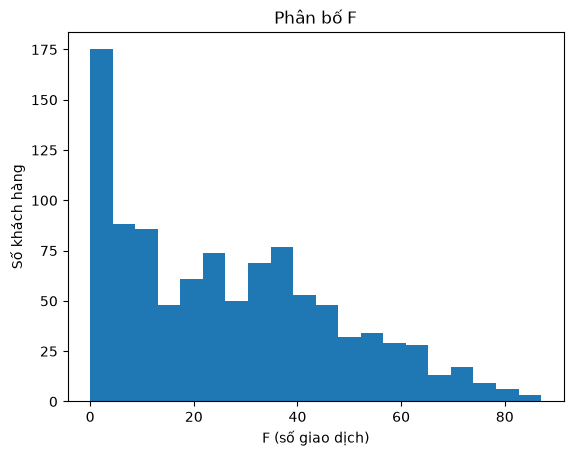

In [9]:
plt.hist(rfm.F, bins=20)
plt.title('Phân bố F')
plt.xlabel('F (số giao dịch)')
plt.ylabel('Số khách hàng')
plt.savefig('output/charts/f_distribution.png')
plt.show()


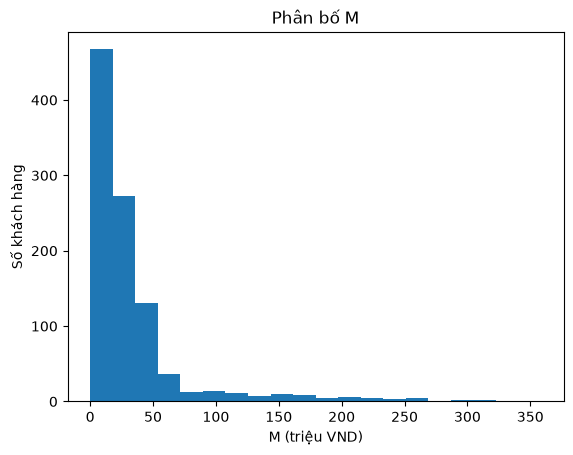

In [10]:
plt.hist(rfm.M / 1e6, bins=20)
plt.title('Phân bố M')
plt.xlabel('M (triệu VND)')
plt.ylabel('Số khách hàng')
plt.savefig('output/charts/m_distribution.png')
plt.show()


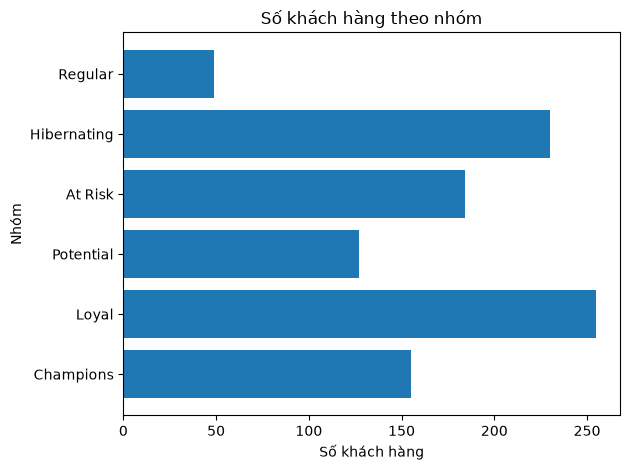

In [11]:
plt.barh(summary.index, summary.customers)
plt.title('Số khách hàng theo nhóm')
plt.xlabel('Số khách hàng')
plt.ylabel('Nhóm')
plt.tight_layout()
plt.savefig('output/charts/segment_sizes.png')
plt.show()


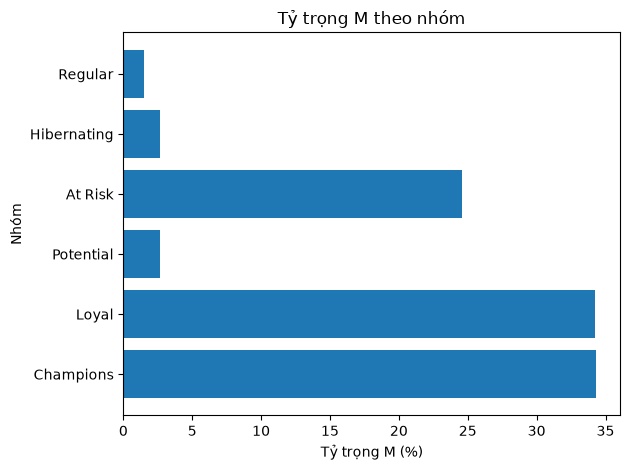

In [12]:
plt.barh(summary.index, summary.M_share_pct)
plt.title('Tỷ trọng M theo nhóm')
plt.xlabel('Tỷ trọng M (%)')
plt.ylabel('Nhóm')
plt.tight_layout()
plt.savefig('output/charts/segment_m_share.png')
plt.show()


In [13]:
for name, row in summary.iterrows():
    print(f"{name}: {int(row.customers)} khách ({row.customer_share_pct:.1f}%), "
          f"chiếm {row.M_share_pct:.1f}% tổng M.")
print('Tỷ lệ M của 10% khách có M lớn nhất:',
      round(rfm.M.nlargest(int(len(rfm) * 0.1)).sum() / rfm.M.sum() * 100, 1), '%')


Champions: 155 khách (15.5%), chiếm 34.3% tổng M.
Loyal: 255 khách (25.5%), chiếm 34.2% tổng M.
Potential: 127 khách (12.7%), chiếm 2.7% tổng M.
At Risk: 184 khách (18.4%), chiếm 24.6% tổng M.
Hibernating: 230 khách (23.0%), chiếm 2.6% tổng M.
Regular: 49 khách (4.9%), chiếm 1.5% tổng M.
Tỷ lệ M của 10% khách có M lớn nhất: 46.0 %


### Hành động CRM cho ba nhóm

Các KPI dưới đây là **đề xuất đo lường**, chưa phải kết quả chiến dịch. Chia ngẫu nhiên nhóm nhận chiến dịch và nhóm đối chứng trong từng segment, so sánh sau 30 ngày.

| Nhóm | Hành động cụ thể | KPI chính và cách tính |
|---|---|---|
| Champions | Hỗ trợ ưu tiên, giới thiệu thanh toán hóa đơn định kỳ; không giảm phí đại trà | Tỷ lệ còn hoạt động 30 ngày = số người có ít nhất 1 giao dịch hợp lệ / số khách của nhánh thử nghiệm; đo chênh lệch với đối chứng |
| Potential | Hướng dẫn dùng thanh toán thẻ/hóa đơn, ưu đãi nhỏ khi phát sinh giao dịch thứ hai | Tỷ lệ có ít nhất 2 giao dịch trong 30 ngày và F trung bình mỗi khách; đo mức tăng so với đối chứng |
| At Risk | Nhắc quay lại, hỏi vướng mắc và thử ưu đãi có giới hạn | Tỷ lệ tái hoạt động 30 ngày = số khách có giao dịch hợp lệ / số khách trong nhánh; chi phí trên một khách tái hoạt động tăng thêm so với đối chứng |

Theo dõi thêm số người từ chối nhận tin, chi phí ưu đãi và phản hồi tiêu cực. Với ngân sách nhỏ, ưu tiên thử trên At Risk có M quá khứ cao và đã đồng ý nhận liên hệ; chỉ mở rộng khi có mức tăng so với đối chứng và chi phí hợp lý. M cao không chứng minh khách mang lại lợi nhuận cao.

### Trả lời câu hỏi thảo luận

1. Cùng M nhưng một khách chỉ chuyển một lần, khách kia thanh toán nhiều lần: M_score có thể giống nhau, F_score khác nhau; R tùy ngày giao dịch gần nhất. Khách giao dịch đều chưa chắc là người có lợi nhuận cao hơn.
2. Tiền chuyển vào không tự động là chi tiêu, có thể là lương hoặc chuyển giữa các tài khoản; cộng vào M chi ra sẽ sai ý nghĩa và có nguy cơ đếm dòng tiền hai lần.
3. Khi ngân sách hạn chế, chọn thử một phần At Risk theo chính sách trên, dùng đối chứng để kiểm tra hiệu quả trước khi chi rộng.


## 5. Tư duy phản biện và hướng cải thiện

**Đặc trưng bổ sung:**

- **Tenure** = số ngày từ `open_date` đến ngày đánh giá: giúp tách khách mới chưa có nhiều thời gian giao dịch khỏi khách lâu năm ít hoạt động.
- **Xu hướng 90 ngày** = (F 90 ngày gần nhất - F 90 ngày trước đó) / F 90 ngày trước đó. Nếu kỳ trước bằng 0, để trống tỷ lệ và xem hai số đếm, không chia cho 0.
- Có thể thêm tỷ lệ giao dịch số: số giao dịch qua Mobile/Web / F; F = 0 thì để trống. Cần kiểm tra ý nghĩa kênh vì bộ dữ liệu có giao dịch thẻ đi kèm nhãn kênh ATM hoặc Branch.

**Hạn chế RFM:** chỉ tóm tắt quá khứ, không phản ánh số dư, nhu cầu vay, phí, chi phí phục vụ, rủi ro tín dụng hay lợi nhuận. Một lần chuyển khoản lớn có thể làm M cao. RFM không cho thấy mùa vụ hoặc nhịp giao dịch; nhóm F = 0 còn gộp cả khách mới và khách đã ngừng hoạt động. R chỉ dùng kỳ 12 tháng nên không biết lần hoạt động cũ hơn của khách không hoạt động.

**Leakage và bias:** chỉ dùng giao dịch trước 01/10/2026; không dùng `synthetic_profile_hint` làm feature, nhãn hoặc bằng chứng đánh giá. Không dùng kết quả chiến dịch tương lai để chọn ngưỡng hiện tại. Điểm F và M có thể bất lợi cho khách mới hoặc người có thu nhập thấp; loại tiền vào/tiền gửi làm nhóm dùng tiết kiệm trông kém hoạt động. Tuổi, thành phố không dùng chấm điểm nhưng nên so sánh tỷ lệ phân nhóm theo các thuộc tính này để phát hiện chênh lệch. Dữ liệu giả lập không bảo đảm phản ánh ngân hàng thực tế.

**Đánh giá độ ổn định:** chạy lại hàng tháng với cùng quy tắc và cửa sổ 12 tháng trượt; lập bảng chuyển nhóm và tỷ lệ giữ nguyên nhóm. Thử thay ngưỡng một chút để xem khách sát ranh giới có đổi nhóm nhiều không. Khi so sánh theo thời gian, thử cả ngưỡng cố định tại kỳ gốc lẫn phân vị tính lại, vì phân vị mới có thể gây đổi nhóm dù hành vi ít đổi. Có thể backtest ngày 01/09/2026 với cửa sổ 01/09/2025 - 31/08/2026 và chỉ dùng thông tin có trước mốc đó. Cần thêm dữ liệu sau ngày đánh giá để kiểm chứng độ ổn định dài hạn. Không dùng silhouette/accuracy hay metadata giả lập để tuyên bố nhóm đúng.

Đây là phân nhóm mô tả để chọn đối tượng thử nghiệm CRM, chưa phải mô hình dự báo rời bỏ hay bằng chứng hiệu quả chiến dịch.
